<a href="https://colab.research.google.com/github/Cloud-Architect-Emma/minillm-research-lab/blob/main/06_end_to_end_training_optimisation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import sys, json, time, math, random, hashlib, gc
from pathlib import Path
from urllib.request import urlretrieve
from contextlib import nullcontext

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

ROOT = Path("minillm_lab6")
RESULTS = ROOT / "results"
FIGURES = RESULTS / "figures"
CHECKPOINTS = ROOT / "checkpoints"

for folder in (RESULTS, FIGURES, CHECKPOINTS):
    folder.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

SEED = 42

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

# Stable settings; exact reproducibility still
# depends on hardware and backend operations.
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.backends.cuda.matmul.allow_tf32 = False

print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("Ready")


PyTorch: 2.14.1+cu130
Device: cuda
GPU: Tesla T4
Ready


In [2]:

data_path = ROOT / "tiny_shakespeare.txt"
url = (
    "https://raw.githubusercontent.com/karpathy/"
    "char-rnn/master/data/tinyshakespeare/input.txt"
)

if not data_path.exists():
    urlretrieve(url, data_path)

raw = data_path.read_bytes()
text = raw.decode("utf-8")
dataset_hash = hashlib.sha256(raw).hexdigest()

chars = sorted(set(text))
stoi = {c: i for i, c in enumerate(chars)}
itos = {i: c for c, i in stoi.items()}

def encode(s):
    return [stoi[c] for c in s]

def decode(ids):
    return "".join(itos[int(i)] for i in ids)

tokens = torch.tensor(encode(text), dtype=torch.long)

train_end = int(len(tokens) * 0.90)
val_end = int(len(tokens) * 0.95)

train_data = tokens[:train_end]
val_data = tokens[train_end:val_end]
test_data = tokens[val_end:]

VOCAB_SIZE = len(chars)

print("Vocabulary:", VOCAB_SIZE)
print("Training tokens:", len(train_data))
print("Validation tokens:", len(val_data))
print("Reserved test tokens:", len(test_data))
print("Dataset SHA256:", dataset_hash)

assert decode(encode("Hello")) == "Hello"


Vocabulary: 65
Training tokens: 1003854
Validation tokens: 55770
Reserved test tokens: 55770
Dataset SHA256: 86c4e6aa9db7c042ec79f339dcb96d42b0075e16b8fc2e86bf0ca57e2dc565ed


In [3]:

CFG = {
    "block_size": 128,
    "embedding_size": 128,
    "heads": 4,
    "layers": 4,
    "batch_size": 16,
    "learning_rate": 3e-4,
    "weight_decay": 0.01,
    "steps": 80,
    "warmup_steps": 5,
    "eval_batches": 12,
    "dropout": 0.0,
}

assert CFG["embedding_size"] % CFG["heads"] == 0

TOKENS_PER_STEP = (
    CFG["batch_size"] * CFG["block_size"]
)

print("Tokens per step:", TOKENS_PER_STEP)
print(json.dumps(CFG, indent=2))


Tokens per step: 2048
{
  "block_size": 128,
  "embedding_size": 128,
  "heads": 4,
  "layers": 4,
  "batch_size": 16,
  "learning_rate": 0.0003,
  "weight_decay": 0.01,
  "steps": 80,
  "warmup_steps": 5,
  "eval_batches": 12,
  "dropout": 0.0
}


In [4]:

def manual_attention(q, k, v):
    T = q.size(-2)
    D = q.size(-1)

    scores = (
        q @ k.transpose(-2, -1)
    ) * (D ** -0.5)

    mask = torch.ones(
        T, T,
        dtype=torch.bool,
        device=q.device
    ).tril()

    scores = scores.masked_fill(~mask, float("-inf"))
    weights = F.softmax(scores, dim=-1)

    return weights @ v


def sdpa_attention(q, k, v):
    return F.scaled_dot_product_attention(
        q, k, v,
        attn_mask=None,
        dropout_p=0.0,
        is_causal=True
    )


class Attention(nn.Module):
    def __init__(self, kind):
        super().__init__()
        assert kind in ("manual", "sdpa")

        C = CFG["embedding_size"]
        self.kind = kind
        self.heads = CFG["heads"]
        self.head_dim = C // self.heads

        self.qkv = nn.Linear(C, 3 * C, bias=False)
        self.proj = nn.Linear(C, C)

    def forward(self, x):
        B, T, C = x.shape

        qkv = self.qkv(x)
        q, k, v = qkv.chunk(3, dim=-1)

        def split(t):
            return t.reshape(
                B, T, self.heads, self.head_dim
            ).transpose(1, 2)

        q, k, v = map(split, (q, k, v))

        if self.kind == "manual":
            out = manual_attention(q, k, v)
        else:
            out = sdpa_attention(q, k, v)

        out = out.transpose(1, 2)
        out = out.contiguous().reshape(B, T, C)

        return self.proj(out)

print("Attention implementations ready")


Attention implementations ready


In [5]:

class TransformerBlock(nn.Module):
    def __init__(self, kind):
        super().__init__()

        C = CFG["embedding_size"]

        self.ln1 = nn.LayerNorm(C)
        self.attn = Attention(kind)
        self.ln2 = nn.LayerNorm(C)

        self.ffn = nn.Sequential(
            nn.Linear(C, 4 * C),
            nn.GELU(),
            nn.Linear(4 * C, C)
        )

    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        x = x + self.ffn(self.ln2(x))
        return x


class MiniGPT(nn.Module):
    def __init__(self, kind):
        super().__init__()

        C = CFG["embedding_size"]
        T = CFG["block_size"]

        self.token_emb = nn.Embedding(VOCAB_SIZE, C)
        self.pos_emb = nn.Embedding(T, C)

        self.blocks = nn.Sequential(*[
            TransformerBlock(kind)
            for _ in range(CFG["layers"])
        ])

        self.ln_f = nn.LayerNorm(C)
        self.head = nn.Linear(C, VOCAB_SIZE)

    def forward(self, idx, targets=None):
        B, T = idx.shape

        if T > CFG["block_size"]:
            raise ValueError("Context window exceeded")

        pos = torch.arange(T, device=idx.device)

        x = self.token_emb(idx) + self.pos_emb(pos)
        x = self.blocks(x)
        logits = self.head(self.ln_f(x))

        loss = None
        if targets is not None:
            loss = F.cross_entropy(
                logits.reshape(-1, VOCAB_SIZE),
                targets.reshape(-1)
            )

        return logits, loss


set_seed(SEED)
reference_model = MiniGPT("manual")

INITIAL_WEIGHTS = {
    k: v.detach().clone()
    for k, v in reference_model.state_dict().items()
}

parameter_count = sum(
    p.numel() for p in reference_model.parameters()
)

print("Trainable parameters:", parameter_count)


Trainable parameters: 824897


In [6]:

manual_model = MiniGPT("manual").to(DEVICE)
sdpa_model = MiniGPT("sdpa").to(DEVICE)

manual_model.load_state_dict(INITIAL_WEIGHTS)
sdpa_model.load_state_dict(INITIAL_WEIGHTS)

manual_model.eval()
sdpa_model.eval()

sample = torch.randint(
    0, VOCAB_SIZE,
    (2, CFG["block_size"]),
    device=DEVICE
)

targets = torch.randint(
    0, VOCAB_SIZE,
    sample.shape,
    device=DEVICE
)

manual_logits, manual_loss = manual_model(
    sample, targets
)

sdpa_logits, sdpa_loss = sdpa_model(
    sample, targets
)

torch.testing.assert_close(
    manual_logits,
    sdpa_logits,
    rtol=1e-4,
    atol=1e-5
)

manual_loss.backward()
sdpa_loss.backward()

for (name1, p1), (name2, p2) in zip(
    manual_model.named_parameters(),
    sdpa_model.named_parameters()
):
    assert name1 == name2

    torch.testing.assert_close(
        p1.grad,
        p2.grad,
        rtol=1e-3,
        atol=1e-5
    )

print("PASS: Full-model outputs agree")
print("PASS: Full-model gradients agree")

del manual_model, sdpa_model
gc.collect()
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()


PASS: Full-model outputs agree
PASS: Full-model gradients agree


In [7]:

def make_batches(data, count, seed):
    generator = torch.Generator().manual_seed(seed)

    B = CFG["batch_size"]
    T = CFG["block_size"]

    batches = []

    for _ in range(count):
        starts = torch.randint(
            0, len(data) - T,
            (B,),
            generator=generator
        )

        x = torch.stack([
            data[i:i+T] for i in starts
        ])

        y = torch.stack([
            data[i+1:i+T+1] for i in starts
        ])

        batches.append((x, y))

    return batches


TRAIN_BATCHES = make_batches(
    train_data,
    CFG["steps"] + CFG["warmup_steps"],
    seed=2026
)

VAL_BATCHES = make_batches(
    val_data,
    CFG["eval_batches"],
    seed=2027
)

assert len(TRAIN_BATCHES) == (
    CFG["steps"] + CFG["warmup_steps"]
)

print("Training batches:", len(TRAIN_BATCHES))
print("Validation batches:", len(VAL_BATCHES))
print("PASS: Fixed batches prepared")


Training batches: 85
Validation batches: 12
PASS: Fixed batches prepared


In [8]:

def make_batches(data, count, seed):
    generator = torch.Generator().manual_seed(seed)

    B = CFG["batch_size"]
    T = CFG["block_size"]

    batches = []

    for _ in range(count):
        starts = torch.randint(
            0, len(data) - T,
            (B,),
            generator=generator
        )

        x = torch.stack([
            data[i:i+T] for i in starts
        ])

        y = torch.stack([
            data[i+1:i+T+1] for i in starts
        ])

        batches.append((x, y))

    return batches


TRAIN_BATCHES = make_batches(
    train_data,
    CFG["steps"] + CFG["warmup_steps"],
    seed=2026
)

VAL_BATCHES = make_batches(
    val_data,
    CFG["eval_batches"],
    seed=2027
)

assert len(TRAIN_BATCHES) == (
    CFG["steps"] + CFG["warmup_steps"]
)

print("Training batches:", len(TRAIN_BATCHES))
print("Validation batches:", len(VAL_BATCHES))
print("PASS: Fixed batches prepared")


Training batches: 85
Validation batches: 12
PASS: Fixed batches prepared


In [9]:

@torch.no_grad()
def evaluate(model, batches):
    model.eval()

    weighted_loss = 0.0
    total_tokens = 0

    for x_cpu, y_cpu in batches:
        x = x_cpu.to(DEVICE)
        y = y_cpu.to(DEVICE)

        _, loss = model(x, y)

        count = y.numel()
        weighted_loss += loss.item() * count
        total_tokens += count

    return weighted_loss / total_tokens


In [10]:

EXPERIMENTS = [
    {"name": "manual_fp32", "attention": "manual", "amp": False},
    {"name": "sdpa_fp32", "attention": "sdpa", "amp": False},
]

if DEVICE.type == "cuda":
    EXPERIMENTS += [
        {"name": "manual_fp16", "attention": "manual", "amp": True},
        {"name": "sdpa_fp16", "attention": "sdpa", "amp": True},
    ]

display(pd.DataFrame(EXPERIMENTS))


,name,attention,amp
0,manual_fp32,manual,False
1,sdpa_fp32,sdpa,False
2,manual_fp16,manual,True
3,sdpa_fp16,sdpa,True


In [11]:

def make_scaler(enabled):
    return torch.amp.GradScaler(
        "cuda",
        enabled=enabled
    )


def training_step(
    model, optimizer, scaler,
    x, y, use_amp
):
    model.train()
    optimizer.zero_grad(set_to_none=True)

    with torch.autocast(
        device_type=DEVICE.type,
        dtype=torch.float16 if DEVICE.type == "cuda"
              else torch.bfloat16,
        enabled=use_amp
    ):
        _, loss = model(x, y)

    if use_amp:
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
    else:
        loss.backward()
        optimizer.step()

    return loss.detach().item()


print("Training step ready")


Training step ready


In [12]:

def sync_gpu():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()


def run_experiment(spec, seed=42, save=True):
    set_seed(seed)

    model = MiniGPT(spec["attention"]).to(DEVICE)
    model.load_state_dict(INITIAL_WEIGHTS)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=CFG["learning_rate"],
        weight_decay=CFG["weight_decay"]
    )

    use_amp = spec["amp"]
    scaler = make_scaler(use_amp)

    initial_val = evaluate(model, VAL_BATCHES)

    def step_from_batch(batch):
        x_cpu, y_cpu = batch
        x = x_cpu.to(DEVICE)
        y = y_cpu.to(DEVICE)

        scale_before = scaler.get_scale() if use_amp else None

        loss = training_step(
            model, optimizer, scaler,
            x, y, use_amp
        )

        scale_after = scaler.get_scale() if use_amp else None

        skipped = (
            use_amp and scale_after < scale_before
        )

        return loss, skipped

    # Warm-up updates: identical batches across variants
    for batch in TRAIN_BATCHES[:CFG["warmup_steps"]]:
        step_from_batch(batch)

    sync_gpu()

    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()

    timings = []
    losses = []
    skipped_updates = 0

    for index, batch in enumerate(
        TRAIN_BATCHES[
            CFG["warmup_steps"]:
            CFG["warmup_steps"] + CFG["steps"]
        ],
        start=1
    ):
        sync_gpu()
        start = time.perf_counter()

        loss, skipped = step_from_batch(batch)

        sync_gpu()
        elapsed = time.perf_counter() - start

        timings.append(elapsed)
        losses.append(loss)
        skipped_updates += int(skipped)

    total_seconds = sum(timings)

    peak_memory_mib = (
        torch.cuda.max_memory_allocated() / (1024 ** 2)
        if DEVICE.type == "cuda"
        else None
    )

    final_val = evaluate(model, VAL_BATCHES)

    measured_tokens = CFG["steps"] * TOKENS_PER_STEP

    result = {
        "experiment": spec["name"],
        "attention": spec["attention"],
        "precision": "mixed_fp16" if use_amp else "fp32",
        "seed": seed,
        "parameters": sum(p.numel() for p in model.parameters()),
        "measured_steps": CFG["steps"],
        "warmup_steps": CFG["warmup_steps"],
        "training_tokens": measured_tokens,
        "initial_val_loss": initial_val,
        "final_val_loss": final_val,
        "training_seconds": total_seconds,
        "median_step_ms": float(np.median(timings) * 1000),
        "tokens_per_second": measured_tokens / total_seconds,
        "peak_gpu_memory_mib": peak_memory_mib,
        "skipped_updates": skipped_updates,
        "gpu": (
            torch.cuda.get_device_name(0)
            if DEVICE.type == "cuda" else "CPU"
        )
    }

    if save:
        torch.save({
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "spec": spec,
            "config": CFG,
            "seed": seed,
            "chars": chars
        }, CHECKPOINTS / f"{spec['name']}_seed{seed}.pt")

    del model, optimizer, scaler
    gc.collect()

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

    return result, losses, timings


print("End-to-end experiment runner ready")


End-to-end experiment runner ready


In [13]:

pilot_result, pilot_losses, pilot_timings = run_experiment(
    EXPERIMENTS[0],
    seed=SEED,
    save=False
)

display(pd.DataFrame([pilot_result]))
print("PASS: Pilot completed")


,experiment,attention,precision,seed,parameters,measured_steps,warmup_steps,training_tokens,initial_val_loss,final_val_loss,training_seconds,median_step_ms,tokens_per_second,peak_gpu_memory_mib,skipped_updates,gpu
0,manual_fp32,manual,fp32,42,824897,80,5,163840,4.327536,2.728244,0.875608,10.480809,187115.635345,126.42334,0,Tesla T4


PASS: Pilot completed


In [14]:

all_results = []
all_loss_logs = []
all_timing_logs = []

for spec in EXPERIMENTS:
    print("\nRunning:", spec["name"])

    result, losses, timings = run_experiment(
        spec,
        seed=SEED,
        save=True
    )

    all_results.append(result)

    for i, loss in enumerate(losses, start=1):
        all_loss_logs.append({
            "experiment": spec["name"],
            "step": i,
            "loss": loss
        })

    for i, seconds in enumerate(timings, start=1):
        all_timing_logs.append({
            "experiment": spec["name"],
            "step": i,
            "milliseconds": seconds * 1000
        })

    pd.DataFrame(all_results).to_csv(
        RESULTS / "primary_results.csv",
        index=False
    )

results_df = pd.DataFrame(all_results)
loss_df = pd.DataFrame(all_loss_logs)
timing_df = pd.DataFrame(all_timing_logs)

loss_df.to_csv(RESULTS / "training_losses.csv", index=False)
timing_df.to_csv(RESULTS / "step_timings.csv", index=False)

display(results_df.round(4))
print("ALL PRIMARY EXPERIMENTS COMPLETE")



Running: manual_fp32

Running: sdpa_fp32

Running: manual_fp16

Running: sdpa_fp16


,experiment,attention,precision,seed,parameters,measured_steps,warmup_steps,training_tokens,initial_val_loss,final_val_loss,training_seconds,median_step_ms,tokens_per_second,peak_gpu_memory_mib,skipped_updates,gpu
0,manual_fp32,manual,fp32,42,824897,80,5,163840,4.3275,2.7282,0.8692,10.5231,188494.5065,126.4233,0,Tesla T4
1,sdpa_fp32,sdpa,fp32,42,824897,80,5,163840,4.3275,2.7282,0.6199,7.4625,264319.0288,112.2397,0,Tesla T4
2,manual_fp16,manual,mixed_fp16,42,824897,80,5,163840,4.3275,2.7282,1.0780,12.8962,151980.6772,108.1719,0,Tesla T4
3,sdpa_fp16,sdpa,mixed_fp16,42,824897,80,5,163840,4.3275,2.7282,0.7754,9.4827,211300.4271,84.4883,0,Tesla T4


ALL PRIMARY EXPERIMENTS COMPLETE


In [15]:

baseline = results_df.loc[
    results_df["experiment"] == "manual_fp32"
].iloc[0]

comparison = results_df.copy()

comparison["speedup_vs_manual_fp32"] = (
    baseline["training_seconds"]
    / comparison["training_seconds"]
)

comparison["validation_loss_change"] = (
    comparison["final_val_loss"]
    - baseline["final_val_loss"]
)

display(comparison[[
    "experiment",
    "training_seconds",
    "tokens_per_second",
    "speedup_vs_manual_fp32",
    "peak_gpu_memory_mib",
    "final_val_loss",
    "validation_loss_change",
    "skipped_updates"
]].round(4))

comparison.to_csv(
    RESULTS / "comparison.csv",
    index=False
)


,experiment,training_seconds,tokens_per_second,speedup_vs_manual_fp32,peak_gpu_memory_mib,final_val_loss,validation_loss_change,skipped_updates
0,manual_fp32,0.8692,188494.5065,1.0000,126.4233,2.7282,0.0,0
1,sdpa_fp32,0.6199,264319.0288,1.4023,112.2397,2.7282,0.0,0
2,manual_fp16,1.0780,151980.6772,0.8063,108.1719,2.7282,-0.0,0
3,sdpa_fp16,0.7754,211300.4271,1.1210,84.4883,2.7282,-0.0,0


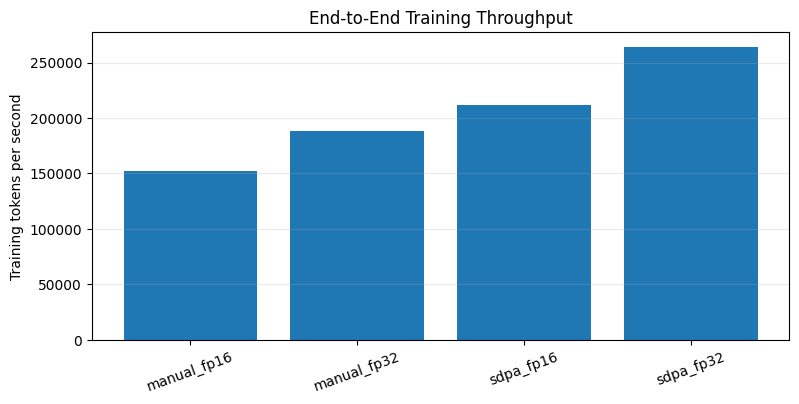

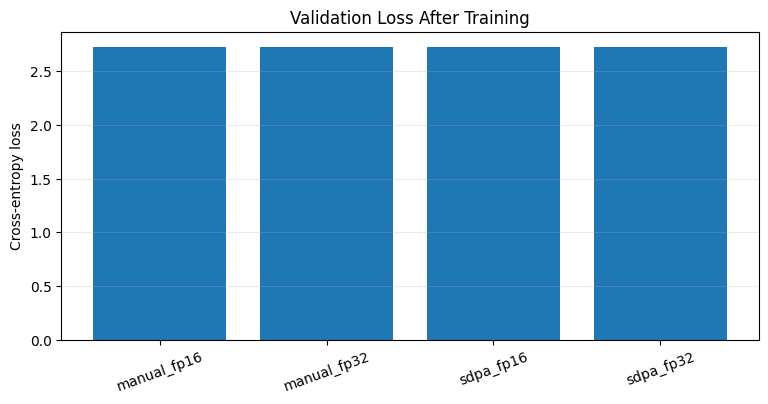

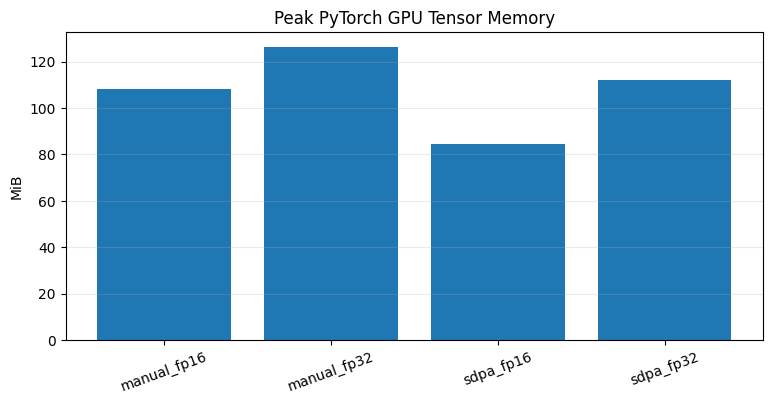

In [16]:

def save_bar_chart(column, title, ylabel, filename):
    data = comparison.sort_values("experiment")

    plt.figure(figsize=(9, 4))
    plt.bar(data["experiment"], data[column])

    plt.title(title)
    plt.ylabel(ylabel)
    plt.xticks(rotation=20)
    plt.grid(axis="y", alpha=0.25)

    plt.savefig(
        FIGURES / filename,
        dpi=160,
        bbox_inches="tight"
    )
    plt.show()


save_bar_chart(
    "tokens_per_second",
    "End-to-End Training Throughput",
    "Training tokens per second",
    "training_throughput.png"
)

save_bar_chart(
    "final_val_loss",
    "Validation Loss After Training",
    "Cross-entropy loss",
    "validation_loss.png"
)

if DEVICE.type == "cuda":
    save_bar_chart(
        "peak_gpu_memory_mib",
        "Peak PyTorch GPU Tensor Memory",
        "MiB",
        "gpu_memory.png"
    )


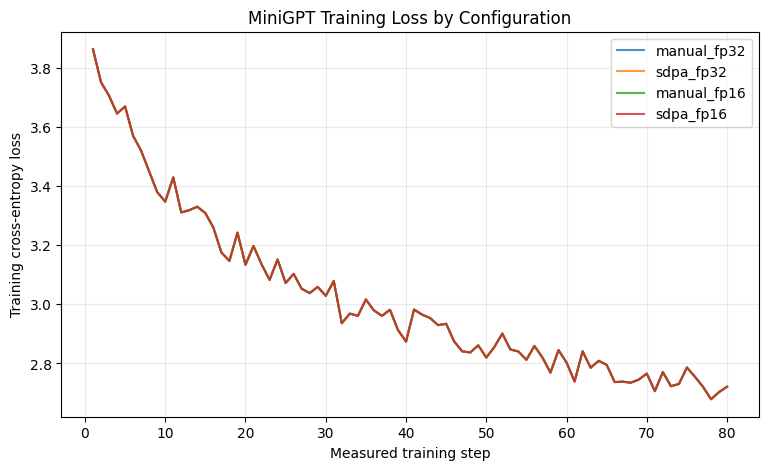

In [17]:

plt.figure(figsize=(9, 5))

for name in loss_df["experiment"].unique():
    subset = loss_df[
        loss_df["experiment"] == name
    ]

    plt.plot(
        subset["step"],
        subset["loss"],
        label=name,
        alpha=0.8
    )

plt.xlabel("Measured training step")
plt.ylabel("Training cross-entropy loss")
plt.title("MiniGPT Training Loss by Configuration")
plt.legend()
plt.grid(True, alpha=0.25)

plt.savefig(
    FIGURES / "training_loss_curves.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()


In [18]:

repeat_results = []

for trial in range(3):
    for spec in EXPERIMENTS[:2]:
        result, _, _ = run_experiment(
            spec,
            seed=SEED,
            save=False
        )

        result["trial"] = trial + 1
        repeat_results.append(result)

repeat_df = pd.DataFrame(repeat_results)

repeat_df.to_csv(
    RESULTS / "repeated_fp32_trials.csv",
    index=False
)

summary = repeat_df.groupby("experiment").agg(
    mean_tokens_per_second=("tokens_per_second", "mean"),
    std_tokens_per_second=("tokens_per_second", "std"),
    mean_training_seconds=("training_seconds", "mean"),
    std_training_seconds=("training_seconds", "std"),
    mean_val_loss=("final_val_loss", "mean")
).reset_index()

display(summary.round(4))

summary.to_csv(
    RESULTS / "repeated_trial_summary.csv",
    index=False
)


,experiment,mean_tokens_per_second,std_tokens_per_second,mean_training_seconds,std_training_seconds,mean_val_loss
0,manual_fp32,190423.1753,2771.4377,0.8605,0.0126,2.7282
1,sdpa_fp32,251621.4280,14359.1468,0.6525,0.0367,2.7282


In [19]:

assert len(results_df) == len(EXPERIMENTS)

assert results_df["training_seconds"].gt(0).all()
assert results_df["tokens_per_second"].gt(0).all()

assert np.isfinite(
    results_df["final_val_loss"]
).all()

assert np.isfinite(
    results_df["initial_val_loss"]
).all()

assert results_df["parameters"].nunique() == 1

assert results_df["training_tokens"].nunique() == 1

for spec in EXPERIMENTS:
    checkpoint = (
        CHECKPOINTS / f"{spec['name']}_seed{SEED}.pt"
    )
    assert checkpoint.exists()

print("PASS: All result checks completed")


PASS: All result checks completed


In [20]:

metadata = {
    "project": "MiniLLM Research Lab",
    "lab": 6,
    "experiment": "End-to-End Attention Optimisation",
    "dataset": "Tiny Shakespeare",
    "dataset_sha256": dataset_hash,
    "dataset_split": {
        "train": 0.90,
        "validation": 0.05,
        "test_reserved": 0.05
    },
    "model_config": CFG,
    "primary_seed": SEED,
    "initial_weights_shared": True,
    "training_batches_shared": True,
    "validation_batches_shared": True,
    "dropout_disabled": True,
    "device": str(DEVICE),
    "gpu": (
        torch.cuda.get_device_name(0)
        if DEVICE.type == "cuda"
        else None
    ),
    "python_version": sys.version,
    "pytorch_version": torch.__version__,
    "cuda_version": torch.version.cuda,
    "experiment_configurations": EXPERIMENTS,
    "timing_scope": (
        "Batch transfer, forward, loss, backward, "
        "gradient scaling if enabled, AdamW update"
    ),
    "memory_metric": "Peak PyTorch CUDA tensor allocation",
    "limitations": [
        "Small character-level transformer",
        "Short training runs",
        "Free Colab hardware variability",
        "SDPA backend not independently identified",
        "Timing repeats do not vary initial weights",
        "Mixed precision can alter optimisation trajectories",
        "Test split not evaluated"
    ]
}

with open(
    RESULTS / "experiment_metadata.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(metadata, f, indent=2)

print("Metadata saved")


Metadata saved


In [21]:

import shutil
from google.colab import files

shutil.make_archive(
    "minillm_lab6_results",
    "zip",
    root_dir=str(ROOT),
    base_dir="results"
)

files.download("minillm_lab6_results.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:

shutil.make_archive(
    "minillm_lab6_checkpoints",
    "zip",
    root_dir=str(ROOT),
    base_dir="checkpoints"
)

files.download("minillm_lab6_checkpoints.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>